In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# blue = population, orange = sample
POP, SAMP, INK, MUTED = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True})

# population = pd.read_csv('diabetes.csv')
population = pd.read_csv('../data/diabetes.csv')
print(population.shape)
population.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
population.describe().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


a. Random sample of 25 – mean and highest Glucose

In [ ]:
SEED = 42
np.random.seed(SEED)

sample = population.sample(n=25, random_state=SEED)

glucose_stats = pd.DataFrame({
    'Population': [population['Glucose'].mean(), population['Glucose'].max()],
    'Sample (n=25)': [sample['Glucose'].mean(), sample['Glucose'].max()],
}, index=['Mean Glucose', 'Highest Glucose']).round(2)
glucose_stats['Difference'] = (glucose_stats['Sample (n=25)'] - glucose_stats['Population']).round(2)
glucose_stats['Difference %'] = (100 * glucose_stats['Difference'] / glucose_stats['Population']).round(2)
glucose_stats

,Population,Sample (n=25),Difference,Difference %
Mean Glucose,120.89,116.64,-4.25,-3.52
Highest Glucose,199.00,183.00,-16.00,-8.04


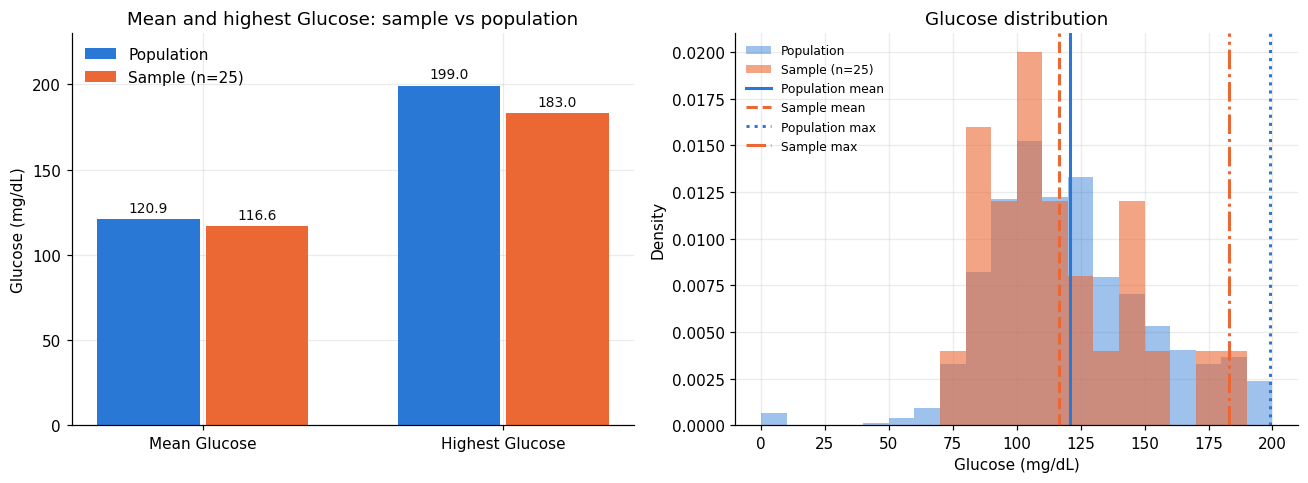

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Chart 1: side-by-side bars for the two statistics
x = np.arange(2); w = 0.36
for i, (col, color) in enumerate([('Population', POP), ('Sample (n=25)', SAMP)]):
    bars = axes[0].bar(x + (i - 0.5) * w, glucose_stats[col], w - 0.02, color=color, label=col)
    axes[0].bar_label(bars, fmt='%.1f', padding=3, color=INK, fontsize=9)
axes[0].set_xticks(x, glucose_stats.index)
axes[0].set_ylabel('Glucose (mg/dL)')
axes[0].set_title('Mean and highest Glucose: sample vs population')
axes[0].legend(frameon=False, loc='upper left')
axes[0].set_ylim(0, 230)

# Chart 2: distributions with the mean and max marked
bins = np.arange(0, 210, 10)
axes[1].hist(population['Glucose'], bins=bins, density=True, color=POP, alpha=0.45, label='Population')
axes[1].hist(sample['Glucose'], bins=bins, density=True, color=SAMP, alpha=0.6, label='Sample (n=25)')
axes[1].axvline(population['Glucose'].mean(), color=POP, lw=2, label='Population mean')
axes[1].axvline(sample['Glucose'].mean(), color=SAMP, lw=2, ls='--', label='Sample mean')
axes[1].axvline(population['Glucose'].max(), color=POP, lw=2, ls=':', label='Population max')
axes[1].axvline(sample['Glucose'].max(), color=SAMP, lw=2, ls='-.', label='Sample max')
axes[1].set_xlabel('Glucose (mg/dL)'); axes[1].set_ylabel('Density')
axes[1].set_title('Glucose distribution')
axes[1].legend(frameon=False, fontsize=8, loc='upper left')

plt.tight_layout(); plt.savefig('../charts/a_glucose_comparison.png', bbox_inches='tight'); plt.show()

### Findings – part A
- **Mean Glucose:** sample 116.64 vs population 120.89, which is 4.25 lower (−3.5%). With only 25 observations the sample mean still lands close to the population mean.
- **Highest Glucose:** sample 183 vs population 199, which is 16 lower (−8.0%). The maximum is harder to estimate than the mean: a sample of 25 rarely includes the single most extreme patient, so **a sample maximum can only equal or understate the population maximum**.
- The histogram shows that the sample covers the middle of the distribution well but misses both tails.

b. 98th percentile of BMI – sample vs population

In [ ]:
bmi_p98 = pd.Series({
    'Population': np.percentile(population['BMI'], 98),
    'Sample (n=25)': np.percentile(sample['BMI'], 98),
}).round(2)
print(bmi_p98)
print(f"Difference: {bmi_p98['Sample (n=25)'] - bmi_p98['Population']:.2f} BMI units")

Population       47.53
Sample (n=25)    40.25
dtype: float64
Difference: -7.28 BMI units


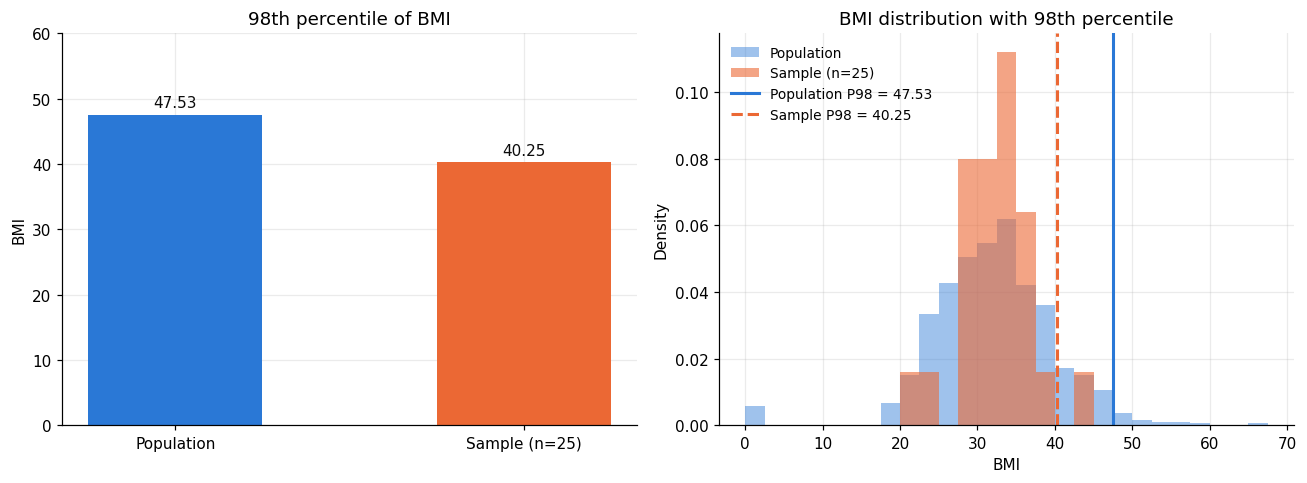

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bars = axes[0].bar(bmi_p98.index, bmi_p98.values, width=0.5, color=[POP, SAMP])
axes[0].bar_label(bars, fmt='%.2f', padding=3, color=INK)
axes[0].set_ylabel('BMI'); axes[0].set_ylim(0, 60)
axes[0].set_title('98th percentile of BMI')

bins = np.arange(0, 70, 2.5)
axes[1].hist(population['BMI'], bins=bins, density=True, color=POP, alpha=0.45, label='Population')
axes[1].hist(sample['BMI'], bins=bins, density=True, color=SAMP, alpha=0.6, label='Sample (n=25)')
axes[1].axvline(bmi_p98['Population'], color=POP, lw=2, label=f"Population P98 = {bmi_p98['Population']}")
axes[1].axvline(bmi_p98['Sample (n=25)'], color=SAMP, lw=2, ls='--', label=f"Sample P98 = {bmi_p98['Sample (n=25)']}")
axes[1].set_xlabel('BMI'); axes[1].set_ylabel('Density')
axes[1].set_title('BMI distribution with 98th percentile')
axes[1].legend(frameon=False, fontsize=9)

plt.tight_layout(); plt.savefig('../charts/b_bmi_p98.png', bbox_inches='tight'); plt.show()

### Findings – part B
- **98th percentile of BMI:** sample 40.25 vs population 47.53, which is 7.28 lower (about −15%).
- This is a much bigger relative gap than for the mean in part (a). With n = 25 the 98th percentile is set by only the top one or two values, so it is very sensitive to which patients happen to be drawn. Our sample contains no patients with BMI above ~44, while the population tail stretches to 67.
- **Takeaway:** small samples estimate the centre of a distribution reasonably well but are unreliable for extreme percentiles.

c. Bootstrap: 500 samples of 150 (with replacement) – BloodPressure

In [ ]:
N_BOOT, N_SIZE, PCT = 500, 150, 98
rng = np.random.default_rng(SEED)
bp = population['BloodPressure'].to_numpy()

boot = []
for i in range(N_BOOT):
    s = rng.choice(bp, size=N_SIZE, replace=True)
    boot.append({'mean': s.mean(), 'std': s.std(ddof=1), 'p98': np.percentile(s, PCT)})
boot = pd.DataFrame(boot)
boot.head()

,mean,std,p98
0,68.346667,21.025707,95.00
1,68.273333,21.284552,92.16
2,69.240000,17.730904,94.00
3,67.540000,18.630865,92.08
4,69.860000,19.016429,102.04


In [ ]:
pop_stats = {'mean': bp.mean(), 'std': bp.std(ddof=0), 'p98': np.percentile(bp, PCT)}

comparison = pd.DataFrame({
    'Population': pop_stats,
    'Bootstrap average': boot.mean(),
    'Bootstrap std error': boot.std(),
}).rename(index={'mean': 'Mean', 'std': 'Standard deviation', 'p98': '98th percentile'})
comparison['Difference'] = comparison['Bootstrap average'] - comparison['Population']
comparison['Difference %'] = 100 * comparison['Difference'] / comparison['Population']
comparison.round(3)

,Population,Bootstrap average,Bootstrap std error,Difference,Difference %
Mean,69.105,69.136,1.530,0.030,0.044
Standard deviation,19.343,19.047,2.173,-0.296,-1.531
98th percentile,99.320,97.888,4.931,-1.432,-1.442


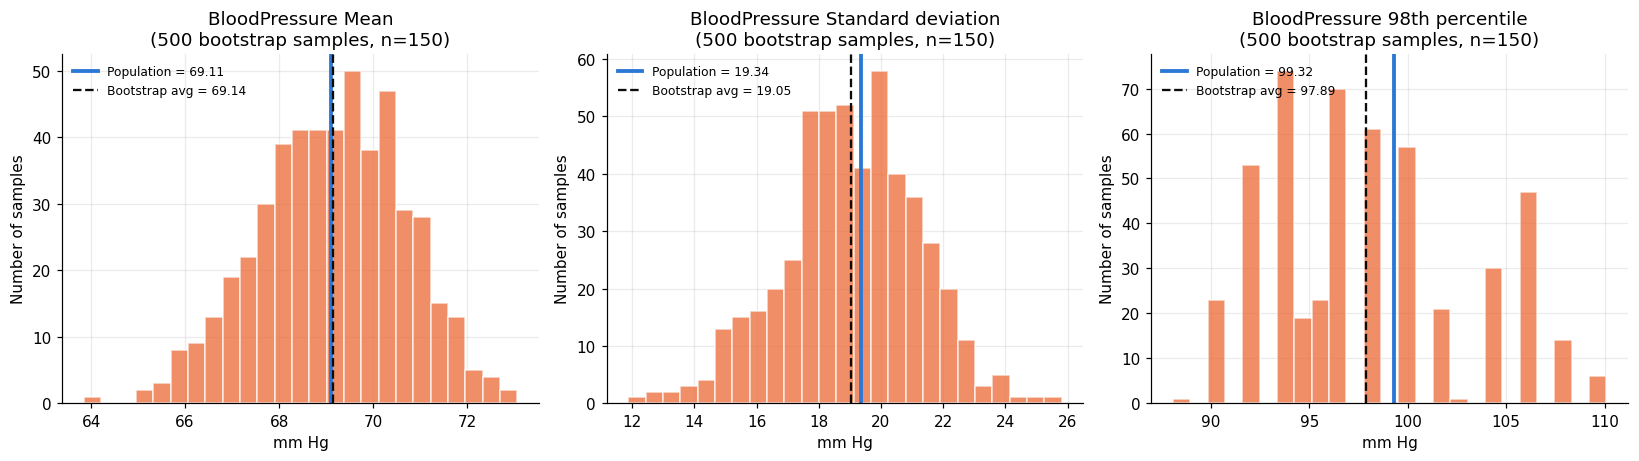

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
labels = {'mean': 'Mean', 'std': 'Standard deviation', 'p98': '98th percentile'}
for ax, key in zip(axes, ['mean', 'std', 'p98']):
    ax.hist(boot[key], bins=25, color=SAMP, alpha=0.75, edgecolor='white')
    ax.axvline(pop_stats[key], color=POP, lw=2.5, label=f'Population = {pop_stats[key]:.2f}')
    ax.axvline(boot[key].mean(), color=INK, lw=1.5, ls='--', label=f'Bootstrap avg = {boot[key].mean():.2f}')
    ax.set_title(f'BloodPressure {labels[key]}\n(500 bootstrap samples, n=150)')
    ax.set_xlabel('mm Hg'); ax.set_ylabel('Number of samples')
    ax.legend(frameon=False, fontsize=8, loc='upper left')

plt.tight_layout(); plt.savefig('../charts/c_bootstrap_distributions.png', bbox_inches='tight'); plt.show()

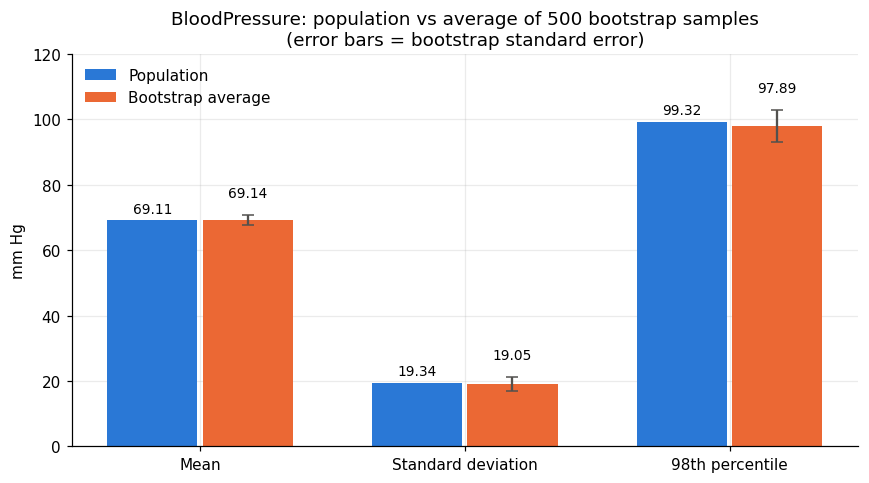

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(3); w = 0.36
b1 = ax.bar(x - w/2, comparison['Population'], w - 0.02, color=POP, label='Population')
b2 = ax.bar(x + w/2, comparison['Bootstrap average'], w - 0.02, color=SAMP, label='Bootstrap average',
            yerr=comparison['Bootstrap std error'], capsize=4, ecolor=MUTED)
ax.bar_label(b1, fmt='%.2f', padding=3, fontsize=9)
ax.bar_label(b2, fmt='%.2f', padding=10, fontsize=9)
ax.set_xticks(x, comparison.index); ax.set_ylabel('mm Hg'); ax.set_ylim(0, 120)
ax.set_title('BloodPressure: population vs average of 500 bootstrap samples\n(error bars = bootstrap standard error)')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.savefig('../charts/c_bootstrap_vs_population.png', bbox_inches='tight'); plt.show()

### Report on findings – part C
| Statistic | Population | Bootstrap average | Difference |
|---|---|---|---|
| Mean | 69.11 | 69.14 | +0.03 (0.04%) |
| Standard deviation | 19.34 | 19.05 | −0.30 (−1.5%) |
| 98th percentile | 99.32 | 97.89 | −1.43 (−1.4%) |

1. **Mean:** almost identical to the population (69.14 vs 69.11). The bootstrap means form a bell curve around the true value (Central Limit Theorem).
2. **Standard deviation:** very close but slightly lower (19.05 vs 19.34). It varies more between samples because of the 35 zero readings.
3. **98th percentile:** the least stable (individual samples range from about 88 to 110) and slightly underestimated (97.89 vs 99.32), because few observations fall in the extreme tail.
4. **Compared with part A:** all three estimates are within ~1.5% of the population, much closer than one sample of 25. Larger, repeated samples reduce sampling error.


**Conclusion:** the bootstrap estimates the mean best and extreme percentiles worst. The more a statistic depends on extreme values, the more data it needs.